# Template Clustering Text
CSV -> bersihin teks -> TF-IDF -> KMeans -> evaluasi -> plot -> insight

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

df = pd.read_csv("Text/BSI-reviews.csv")                        # GANTI nama file
df = df.rename(columns={"content": "corpus"})  # GANTI nama kolom teks
df = df.sample(3000, random_state=42)   # kalau datanya gede, ambil sampel acak
df = df.dropna(subset="corpus").drop_duplicates(subset="corpus").reset_index(drop=True)
print(df.shape)
df.head()

(3000, 12)


,Unnamed: 0,reviewId,userName,userImage,corpus,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,75721,0319b8e0-277f-5fa7-ba13-e205f18b8d7e,Pengguna Sintetis 075722,NaN,Untuk pertama kalinya saya memakai fitur ini. ...,5,0,6.23.0,2024-07-12 15:01:33,Terima kasih atas ulasan Anda. Semoga layanan ...,2024-07-14 04:46:33,6.23.0
1,80184,346ef725-d0ef-517a-963b-cc21c22b68ef,Pengguna Sintetis 080185,NaN,Untuk pertama kalinya saya memakai fitur ini. ...,5,0,6.26.2,2025-09-06 03:11:29,NaN,NaN,6.26.2
2,19864,0b5d04d3-e279-512f-b57c-d9f1f4f04ea9,Pengguna Sintetis 019865,NaN,"Selama memakai aplikasi BSI, Panduan dari laya...",1,0,6.22.0,2024-11-30 22:28:33,NaN,NaN,6.22.0
3,76699,f7649a93-5e98-5f1a-b619-181864817853,Pengguna Sintetis 076700,NaN,Pengiriman uang lewat bi fast cukup membantu t...,3,0,6.24.0,2024-10-22 17:45:54,NaN,NaN,6.24.0
4,92991,b0adc48b-3d6c-5527-9523-b68fbbe4ff7b,Pengguna Sintetis 092992,NaN,Pembayaran tagihan internet rumah kurang nyama...,2,18,6.26.2,2024-10-01 09:06:34,NaN,NaN,6.26.2


## Plot deskriptif

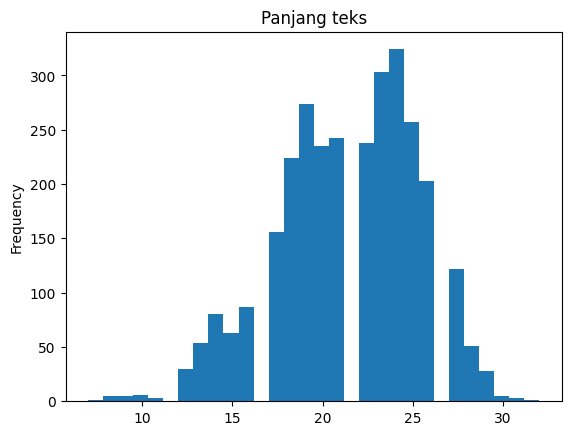

In [19]:
df["jumlah_kata"] = df["corpus"].str.split().str.len()
df["jumlah_kata"].plot(kind="hist", bins=30, title="Panjang teks")
plt.show()

# kalau ada kolom kategori
# df["kategori"].value_counts().plot(kind="bar")
# plt.show()

## Preprocessing

In [20]:
from nltk.corpus import stopwords
stop = set(stopwords.words("indonesian"))   # GANTI "english" kalau bahasa inggris
stop.update(["yg", "ga", "gak", "aja", "banget", "nya"])

def clean(text):
    text = text.lower()
    text = re.sub(r"http\S+", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in stop]
    return " ".join(words)

df["cleaned"] = df["corpus"].apply(clean)
df[["corpus", "cleaned"]].head()

,corpus,cleaned
0,Untuk pertama kalinya saya memakai fitur ini. ...,kalinya memakai fitur penyelesaian laporan cus...
1,Untuk pertama kalinya saya memakai fitur ini. ...,kalinya memakai fitur proses pengaduan transak...
2,"Selama memakai aplikasi BSI, Panduan dari laya...",memakai aplikasi bsi panduan layanan pelanggan...
3,Pengiriman uang lewat bi fast cukup membantu t...,pengiriman uang bi fast membantu konsisten ver...
4,Pembayaran tagihan internet rumah kurang nyama...,pembayaran tagihan internet rumah nyaman diula...


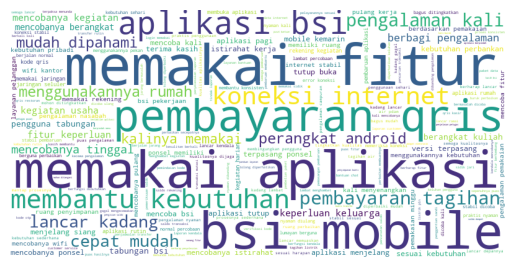

In [21]:
from wordcloud import WordCloud

wc = WordCloud(width=800, height=400, background_color="white").generate(" ".join(df["cleaned"]))
plt.imshow(wc)
plt.axis("off")
plt.show()

## TF-IDF

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

vectorizer = TfidfVectorizer(sublinear_tf=True, min_df=5, max_df=0.95)
X_tfidf = vectorizer.fit_transform(df["cleaned"])   # dipakai lagi buat top keywords

# SVD (PCA-nya teks) biar dimensi kecil, silhouette lebih bagus
X = Normalizer().fit_transform(TruncatedSVD(n_components=5, random_state=42).fit_transform(X_tfidf))
X.shape

(3000, 5)

## Tentukan k

  0%|          | 0/9 [00:00<?, ?it/s]

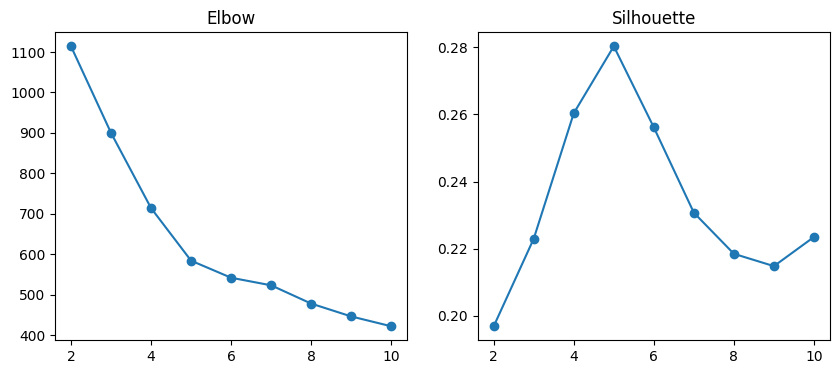

In [23]:
from tqdm.auto import tqdm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

ks = range(2, 11)
inertia, sil = [], []
for k in tqdm(ks):
    km = KMeans(n_clusters=k, random_state=42).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette")
plt.show()

k dipilih = ... karena ... (isi sendiri dari grafik)

## KMeans + evaluasi

In [24]:
k = 5   # GANTI
kmeans = KMeans(n_clusters=k, random_state=42).fit(X)
df["cluster"] = kmeans.labels_

print("Silhouette    :", silhouette_score(X, df["cluster"]))
print("Davies-Bouldin:", davies_bouldin_score(X, df["cluster"]))
print(df["cluster"].value_counts())

Silhouette    : 0.2803325548669147
Davies-Bouldin: 1.085603051978906
cluster
2    738
1    729
3    631
0    472
4    430
Name: count, dtype: int64


## Plot cluster (PCA)

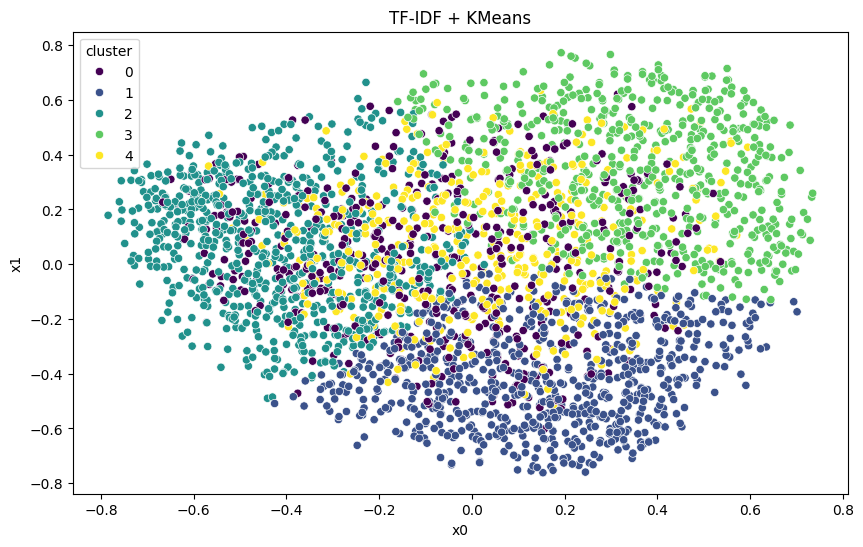

In [25]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pc = pca.fit_transform(X)
df["x0"], df["x1"] = pc[:, 0], pc[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="x0", y="x1", hue="cluster", palette="viridis")
plt.title("TF-IDF + KMeans")
plt.show()

## Insight tiap cluster

In [26]:
terms = vectorizer.get_feature_names_out()
centers = pd.DataFrame(X_tfidf.todense()).groupby(df["cluster"]).mean()

for c, row in centers.iterrows():
    top = [terms[i] for i in np.argsort(row)[-10:][::-1]]
    print(f"Cluster {c}: {', '.join(top)}")
    for t in df[df["cluster"] == c]["corpus"].head(3):
        print("   -", t)

# kalau ada kolom label
# pd.crosstab(df["cluster"], df["kategori"])

Cluster 0: pembayaran, qris, tagihan, pengalaman, mencobanya, rumah, air, pdam, kebutuhan, kasir
   - Pembayaran tagihan internet rumah kurang nyaman karena harus diulang. Saya menggunakan versi yang terpasang di ponsel. Masih banyak yang perlu dibenahi.
   - Untuk pertama kalinya saya memakai fitur ini. Pembayaran qris di restoran lumayan berguna namun masih perlu perbaikan. Saya mencobanya dari tempat tinggal saya.
   - Untuk kebutuhan perbankan saya, Pembayaran tagihan listrik pln cukup cepat dan mudah dipahami. Saya berharap fitur ini terus berkembang.
Cluster 1: kebutuhan, membantu, aplikasi, bsi, menggunakannya, ponsel, pembaruan, mobile, ruang, perbaikan
   - Selama memakai aplikasi BSI, Panduan dari layanan pelanggan buruk dan perlu perbaikan secepatnya. Ponsel saya memiliki ruang penyimpanan cukup. Semoga laporan saya ditindaklanjuti.
   - Pengiriman uang lewat bi fast cukup membantu tetapi belum konsisten. Saya menggunakan versi yang terpasang di ponsel. Saya belum sepenuhnya

## Kesimpulan
- Evaluasi: silhouette = ..., DBI = ...
- Cluster 0: ...
- Cluster 1: ...
- Cluster 2: ...